In [2]:
!pip install qiskit
!pip install qiskit-ibm-runtime
!pip install 'qiskit[visualization]'
!pip install qiskit_serverless
!pip install pylatexenc

!pip install qiskit_aer

In [5]:
import qiskit
print(qiskit.__version__)

1.3.2


In [7]:
from qiskit_ibm_runtime import QiskitRuntimeService

In [8]:
service = QiskitRuntimeService(channel="ibm_quantum", token = 'c287947adfd8dbbe96b534a92d0a500c22baf7995eb68cf849543a9bebd651ddf133fac90d0510ab87b8ecda5bb55c3e345945e5be113df00c45e50495440dd2')

In [9]:
backend = service.backend(name='ibm_kyiv')
print('Number of quibits:', backend.num_qubits)

Number of quibits: 127


# Hello world! 2 Qubits Bell state

In [10]:
from qiskit import QuantumCircuit

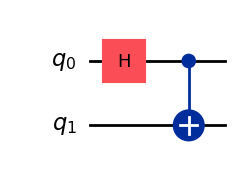

In [12]:
qc = QuantumCircuit(2,1)
qc.h(0)
qc.cx(0,1)
qc.draw(output='mpl')

In [13]:
# Observables for Measurement

from qiskit.quantum_info import Pauli
ZZ = Pauli('ZZ')
ZI = Pauli('ZI')
IZ = Pauli('IZ')
XX = Pauli('XX')
XI = Pauli('XI')
IX = Pauli('IX')
observables = [ZZ,ZI,IZ,XX,XI,IX]

In [16]:
from qiskit_aer.primitives import Estimator

estimator = Estimator()
job = estimator.run([qc]* len(observables), observables)

In [17]:
result = job.result()
print("Measurement Results: ", result)

Measurement Results:  EstimatorResult(values=array([ 1.        , -0.03320312, -0.03320312,  1.        ,  0.01757812,
        0.01757812]), metadata=[{'shots': 1024, 'variance': 0.0, 'simulator_metadata': [{'num_bind_params': 1, 'runtime_parameter_bind': False, 'parallel_state_update': 8, 'parallel_shots': 1, 'sample_measure_time': 0.000373125, 'noise': 'ideal', 'batched_shots_optimization': False, 'remapped_qubits': False, 'active_input_qubits': [0, 1], 'device': 'CPU', 'time_taken': 0.001115709, 'measure_sampling': True, 'num_clbits': 2, 'max_memory_mb': 16384, 'input_qubit_map': [[1, 1], [0, 0]], 'num_qubits': 2, 'method': 'stabilizer', 'required_memory_mb': 0, 'fusion': {'enabled': False}}]}, {'shots': 1024, 'variance': 0.9988975524902344, 'simulator_metadata': [{'num_bind_params': 1, 'runtime_parameter_bind': False, 'parallel_state_update': 8, 'parallel_shots': 1, 'sample_measure_time': 0.000373125, 'noise': 'ideal', 'batched_shots_optimization': False, 'remapped_qubits': False, 'a

In [19]:
job.result().values

array([ 1.        , -0.03320312, -0.03320312,  1.        ,  0.01757812,
        0.01757812])

In [20]:
import matplotlib

# More


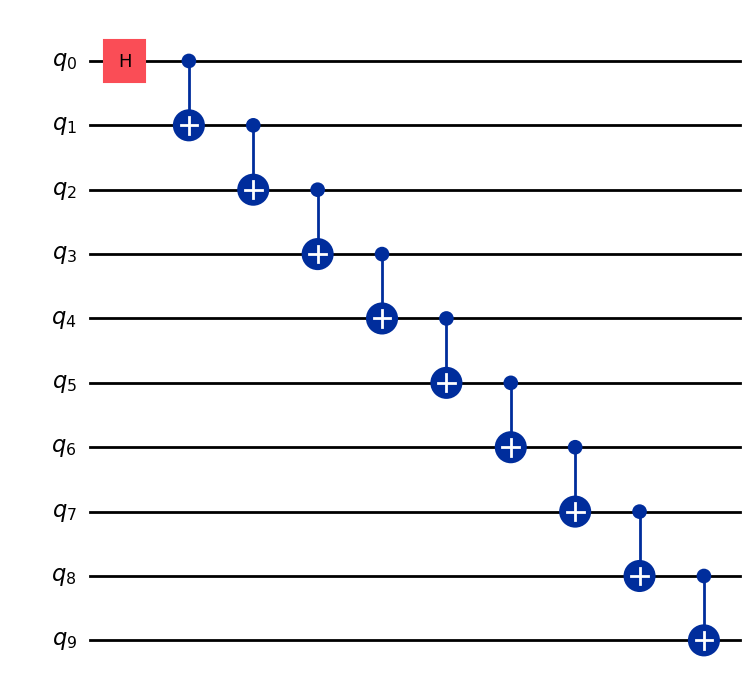

In [38]:
def get_qc_for_nQubit(n):
    qc = QuantumCircuit(n)
    qc.h(0)
    for i in range(n-1):
        qc.cx(i,i+1)
    return qc

n = 10
qc = get_qc_for_nQubit(n)
qc.draw('mpl')

In [39]:
from qiskit.quantum_info import SparsePauliOp

operator_strings= ['Z' + 'I' * i + 'Z' + 'I' * (n-2-i) for i in range (n-1)]
print (*operator_strings, sep='\n')

ZZIIIIIIII
ZIZIIIIIII
ZIIZIIIIII
ZIIIZIIIII
ZIIIIZIIII
ZIIIIIZIII
ZIIIIIIZII
ZIIIIIIIZI
ZIIIIIIIIZ
